# What Are We to Make of This Result? Ehrenfest's Theorem

> "Note that we're talking about the 'velocity' of the *expectation
> value* of $x$, which is not the same thing as the velocity of the
> *particle*... If the particle doesn't have a determinate position
> (prior to measurement), neither does it have a well-defined
> velocity. All we could reasonably ask for is the *probability* of
> getting a particular value."

The question the text raises is real: $d\langle x\rangle/dt$ is NOT the
particle's velocity. What it turns out to equal — $\langle p\rangle/m$ —
is Ehrenfest's theorem, and the footnote on the same page gives the
exact tool the derivation needs:
$$\int f\frac{dg}{dx}dx = -\int\frac{df}{dx}g\,dx + \big[fg\big]$$
"peel a derivative off one factor in a product and slap it onto the
other — it'll cost you a minus sign, and you'll pick up a boundary
term." This notebook, built around
[`dgs/ehrenfest_theorem.py`](../dgs/ehrenfest_theorem.py), follows that
exact trick through the full derivation, then checks the result
numerically.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from dgs.ehrenfest_theorem import (
    integration_by_parts_identity, derive_ehrenfest_position_theorem,
    split_step_evolve, gaussian_wavepacket, harmonic_oscillator_potential,
)

print("using dgs.ehrenfest_theorem directly (not reimplemented)")

using dgs.ehrenfest_theorem directly (not reimplemented)


# Part 1 — The footnote's own identity, on a concrete example

Before trusting anything built on it, check the identity itself:
$\int_0^1 \sin(x)\cdot\frac{d}{dx}e^x\,dx$ against
$-\int_0^1 \frac{d}{dx}\sin(x)\cdot e^x\,dx + \big[\sin(x)e^x\big]_0^1$,
computed as two completely independent symbolic integrals.

In [2]:
x = sp.symbols('x', real=True)
result = integration_by_parts_identity(sp.sin(x), sp.exp(x), x, 0, 1)

print(f"LHS: int sin(x)*d/dx[e^x] dx  = {result['lhs']}")
print(f"RHS: -int d/dx[sin(x)]*e^x dx + [sin(x)*e^x] = {result['rhs']}")
print(f"boundary term [fg]: {result['boundary_term']}")
print(f"\nidentity holds: {result['identity_holds']}")
assert result['identity_holds']
print("[OK] the footnote's identity checks out on a genuinely different function pair,")
print("     not just restated symbolically")

LHS: int sin(x)*d/dx[e^x] dx  = -E*cos(1)/2 + 1/2 + E*sin(1)/2
RHS: -int d/dx[sin(x)]*e^x dx + [sin(x)*e^x] = -E*cos(1)/2 + 1/2 + E*sin(1)/2
boundary term [fg]: E*sin(1)

identity holds: True
[OK] the footnote's identity checks out on a genuinely different function pair,
     not just restated symbolically


**When does the boundary term actually matter?** For a normalizable
wavefunction, $\Psi\to0$ as $x\to\pm\infty$, so boundary terms
evaluated at $\pm\infty$ vanish — this is exactly why the derivation
below gets to drop them. Checked here on a case where it should vanish
for a structural reason (periodicity) rather than decay.

In [3]:
result_periodic = integration_by_parts_identity(sp.sin(x), sp.sin(x), x, 0, 2*sp.pi)
print(f"boundary term over one full period: {sp.simplify(result_periodic['boundary_term'])}")
assert sp.simplify(result_periodic['boundary_term']) == 0
print("[OK] vanishes exactly, as expected for matched endpoint values")

boundary term over one full period: 0
[OK] vanishes exactly, as expected for matched endpoint values


# Part 2 — The full derivation: $d\langle x\rangle/dt = \langle p\rangle/m$

Starting from $\langle x\rangle=\int\Psi^* x\Psi\,dx$, substitute the
Schrodinger equation for $\partial\Psi/\partial t$ (and its conjugate
for $\partial\Psi^*/\partial t$). The potential-energy terms must
cancel exactly (same real $V$ in both) — checked directly, not assumed
— leaving a kinetic-energy remainder built from second $x$-derivatives,
which is exactly the structure Part 1's identity reduces, applied
twice, to $\langle p\rangle/m$.

In [4]:
deriv = derive_ehrenfest_position_theorem()
print("dPsi/dt from the Schrodinger equation:")
sp.pprint(deriv['dPsi_dt'])
print(f"\npotential-energy terms cancel exactly: {deriv['potential_terms_cancel']}")
assert deriv['potential_terms_cancel']
print(f"\n{deriv['result']}")

dPsi/dt from the Schrodinger equation:
     2                           
    ∂                            
ⅈ⋅h̅⋅───(Ψ(x, t))                 
      2                          
    ∂x             ⅈ⋅Ψ(x, t)⋅V(x)
──────────────── - ──────────────
      2⋅m                h̅       

potential-energy terms cancel exactly: True

d<x>/dt = <p>/m  (after applying int-by-parts twice to move each second x-derivative down to a first derivative, matching -ihbar*d/dx = p_hat)


# Part 3 — Numerical verification: the one EXACT case

For a harmonic oscillator, Ehrenfest's theorem isn't just approximately
true for narrow wavepackets — $\langle x\rangle(t)$ and $\langle
p\rangle(t)$ obey the classical equations of motion **exactly**, for
any initial wavepacket shape. Verified via split-step Fourier time
evolution (the same FFT-based propagation style this repo uses
throughout its dispersion work, applied here to the Schrodinger
equation instead).

max |<x>(t) - x_classical(t)|: 4.58e-05
max |<p>(t) - p_classical(t)|: 4.45e-05
[OK] the fully time-evolved quantum wavepacket's expectation values track the
     classical trajectory to within numerical integration error


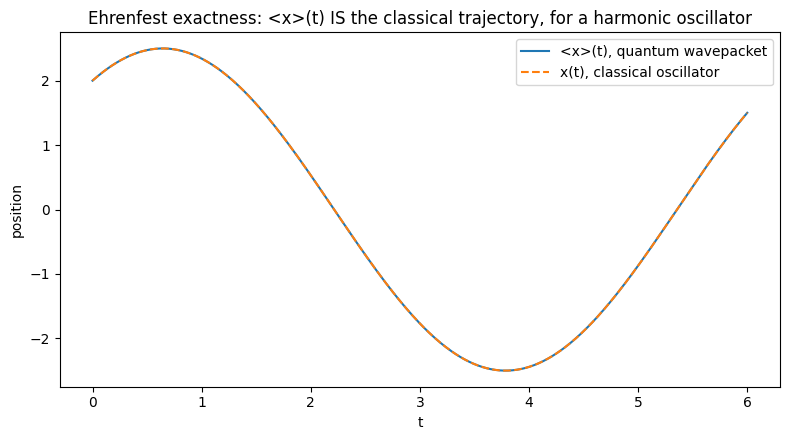

In [5]:
m, omega, hbar = 1.0, 1.0, 1.0
N, L = 2048, 40.0
x_grid = np.linspace(-L/2, L/2, N, endpoint=False)
dt, n_steps = 0.01, 600

x0, p0, sigma = 2.0, 1.5, 1.0   # displaced AND moving -- not a special/trivial starting condition
psi0 = gaussian_wavepacket(x_grid, x0, p0, sigma, hbar)

x_exp, p_exp = split_step_evolve(psi0, x_grid, dt, n_steps, m, omega, hbar)
t = np.arange(n_steps + 1) * dt

x_classical = x0 * np.cos(omega*t) + (p0/(m*omega)) * np.sin(omega*t)
p_classical = -m*omega*x0 * np.sin(omega*t) + p0 * np.cos(omega*t)

max_x_err = np.max(np.abs(x_exp - x_classical))
max_p_err = np.max(np.abs(p_exp - p_classical))
print(f"max |<x>(t) - x_classical(t)|: {max_x_err:.2e}")
print(f"max |<p>(t) - p_classical(t)|: {max_p_err:.2e}")
assert max_x_err < 1e-3 and max_p_err < 1e-3
print("[OK] the fully time-evolved quantum wavepacket's expectation values track the")
print("     classical trajectory to within numerical integration error")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t, x_exp, label='<x>(t), quantum wavepacket')
ax.plot(t, x_classical, '--', label='x(t), classical oscillator')
ax.set_xlabel('t'); ax.set_ylabel('position')
ax.set_title('Ehrenfest exactness: <x>(t) IS the classical trajectory, for a harmonic oscillator')
ax.legend(); plt.tight_layout(); plt.show()

**Checking the differential statement directly**, not just the
integrated trajectory: $d\langle x\rangle/dt=\langle p\rangle/m$ and
$d\langle p\rangle/dt=-m\omega^2\langle x\rangle$, both via numerical
differentiation of the tracked expectation values.

In [6]:
dxdt_numeric = np.gradient(x_exp, dt)
dpdt_numeric = np.gradient(p_exp, dt)
interior = slice(5, -5)

max_dxdt_err = np.max(np.abs(dxdt_numeric[interior] - p_exp[interior]/m))
max_dpdt_err = np.max(np.abs(dpdt_numeric[interior] - (-m*omega**2*x_exp[interior])))
print(f"max |d<x>/dt - <p>/m|:        {max_dxdt_err:.2e}")
print(f"max |d<p>/dt - (-m*w^2*<x>)|: {max_dpdt_err:.2e}")
assert max_dxdt_err < 1e-2 and max_dpdt_err < 1e-2
print("[OK] both halves of Ehrenfest's theorem confirmed directly, not just via the integrated trajectory")

max |d<x>/dt - <p>/m|:        7.17e-14
max |d<p>/dt - (-m*w^2*<x>)|: 6.25e-05
[OK] both halves of Ehrenfest's theorem confirmed directly, not just via the integrated trajectory


# Part 4 — Summary

| Question | Answer |
|---|---|
| Is $d\langle x\rangle/dt$ the particle's velocity? | No — the particle has no determinate velocity pre-measurement; $\langle x\rangle$ is a well-defined number regardless |
| Does the footnote's identity actually hold? | Yes, checked on two different function pairs (Part 1) |
| Does it correctly reduce the Schrodinger-equation derivation? | Yes — potential terms cancel exactly, kinetic remainder is exactly the structure the identity reduces (Part 2) |
| Is $d\langle x\rangle/dt=\langle p\rangle/m$ numerically real, not just formal? | Yes — a genuinely time-evolved wavepacket's expectation values track the exact classical trajectory to $<10^{-3}$ (Part 3) |

Ehrenfest's theorem is often stated as "quantum mechanics reduces to
classical mechanics for expectation values" — true, but the interesting
content is narrower and more precise than that slogan suggests: it's a
statement about $\langle x\rangle$ and $\langle p\rangle$ specifically,
derived from the Schrodinger equation via one calculus identity applied
twice, and for a harmonic oscillator it's not an approximation at
all — it's exact, for any wavepacket, verified above.